# Module 4

### Calling the libraries.

In [134]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

### Preparing the dataset.

In [135]:
df = pd.read_csv('course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [136]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [137]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

In [138]:
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0)

In [139]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               5000 non-null   str    
 1   industry                  5000 non-null   str    
 2   employment_status         5000 non-null   str    
 3   location                  5000 non-null   str    
 4   annual_income             5000 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                5000 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


### Split the data.

In [140]:
from sklearn.model_selection import train_test_split

In [141]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

### Question 1

In [142]:
X_train = df_train.drop('converted', axis=1)
y_train = df_train['converted']

X_val = df_val.drop('converted', axis=1)
y_val = df_val['converted']

X_test = df_test.drop('converted', axis=1)
y_test = df_test['converted']

In [143]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve
from sklearn.metrics import auc

In [144]:
for numerical_col in numerical:
    model = LogisticRegression()
    model.fit(pd.DataFrame(X_train[numerical_col]), y_train)
    y_pred = model.predict(pd.DataFrame(X_val[numerical_col]))
    fpr, tpr, thresholds = roc_curve(y_val, y_pred)
    feature_auc = auc(fpr, tpr)
    print(f'For {numerical_col}: {feature_auc}')

For annual_income: 0.5761693953933158
For number_of_courses_viewed: 0.6572851230812353
For interaction_count: 0.6707803663583453
For lead_score: 0.6957222469538837


### Question 2

In [145]:
from sklearn.feature_extraction import DictVectorizer

In [146]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)


In [147]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [148]:
y_pred = model.predict(X_val)
fpr, tpr, threshold = roc_curve(y_val, y_pred)
auc(fpr, tpr)

0.5979992085868329

### Question 3

In [149]:
from sklearn.metrics import confusion_matrix

y_proba = model.predict_proba(X_val)[:,1]
y_pred = (y_proba >= 0.5)
tn, fp, fn, tp = confusion_matrix(y_val, y_pred).ravel()
print(tn, fp, fn, tp)

120 294 55 531


C:\Users\Win 10\AppData\Local\Temp\ipykernel_43968\986733666.py:11: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp/(tp+fp)
C:\Users\Win 10\AppData\Local\Temp\ipykernel_43968\986733666.py:11: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp/(tp+fp)
C:\Users\Win 10\AppData\Local\Temp\ipykernel_43968\986733666.py:11: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp/(tp+fp)
C:\Users\Win 10\AppData\Local\Temp\ipykernel_43968\986733666.py:11: RuntimeWarning: invalid value encountered in scalar divide
  precision = tp/(tp+fp)


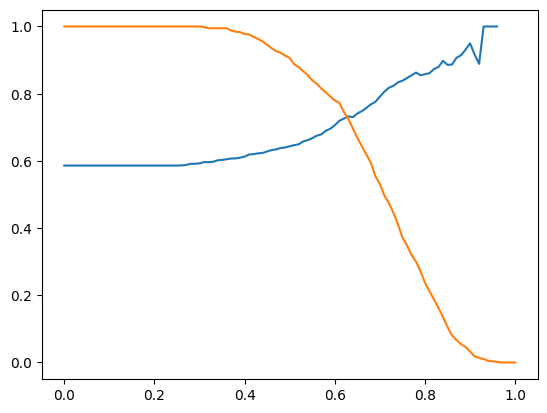

In [150]:
threshold = np.linspace(0, 1, 101)

precision_list = []
recall_list = []

for t in threshold:
    y_proba = model.predict_proba(X_val)[:,1]
    y_pred = (y_proba >= t)
    tn, fp, fn, tp = confusion_matrix(y_val, y_pred).ravel()
    
    precision = tp/(tp+fp)
    recall = tp/(tp+fn)

    precision_list.append(precision)
    recall_list.append(recall)

plt.plot(threshold, precision_list, label='precision')
plt.plot(threshold, recall_list, label='recall')
 

### Question 4

0.7576158940397352


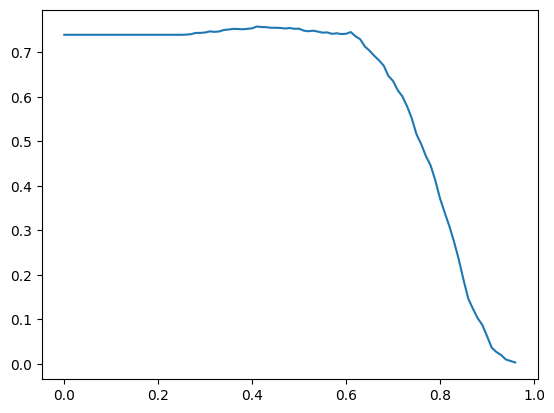

In [151]:
f1_list = []

for p, r in zip(precision_list, recall_list):
    f1_score = 2*p*r/(p+r)
    f1_list.append(f1_score)

print(max(f1_list))
plt.plot(threshold, f1_list, label='f1 scores')

### Question 5

In [159]:
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score

In [165]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [166]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [168]:
model = KFold(n_splits=5, shuffle=True, random_state=1)

In [171]:
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train['converted'].values
    y_val = df_val['converted'].values

    dv, model = train(df_train, y_train, C=1)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print(f'With 5-fold: {np.mean(scores).round(3)} +- {np.std(scores).round(3)}')

With 5-fold: 0.732 +- 0.007


### Question 6

In [170]:
from tqdm.auto import tqdm

saved_list = []

n_splits = 5

for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train['converted'].values
        y_val = df_val['converted'].values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)
    saved_list.append([C, np.mean(scores), np.std(scores)])

for C, mean, std in saved_list:
    print(f'For C={C}: {mean.round(3)} +- {std.round(3)}')

For C=1e-06: 0.617 +- 0.019
For C=0.001: 0.749 +- 0.01
For C=1: 0.732 +- 0.007
